In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from plotnine.data import mpg
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score



In [3]:
# Load the car data
df = mpg.copy()
print(df)

    manufacturer   model  displ  year  cyl       trans drv  cty  hwy fl  \
0           audi      a4    1.8  1999    4    auto(l5)   f   18   29  p   
1           audi      a4    1.8  1999    4  manual(m5)   f   21   29  p   
2           audi      a4    2.0  2008    4  manual(m6)   f   20   31  p   
3           audi      a4    2.0  2008    4    auto(av)   f   21   30  p   
4           audi      a4    2.8  1999    6    auto(l5)   f   16   26  p   
..           ...     ...    ...   ...  ...         ...  ..  ...  ... ..   
229   volkswagen  passat    2.0  2008    4    auto(s6)   f   19   28  p   
230   volkswagen  passat    2.0  2008    4  manual(m6)   f   21   29  p   
231   volkswagen  passat    2.8  1999    6    auto(l5)   f   16   26  p   
232   volkswagen  passat    2.8  1999    6  manual(m5)   f   18   26  p   
233   volkswagen  passat    3.6  2008    6    auto(s6)   f   17   26  p   

       class  
0    compact  
1    compact  
2    compact  
3    compact  
4    compact  
..       

In [4]:

# Choose the features
features = ["displ", "year", "cyl", "cty", "hwy"]
X = df[features]
#

In [5]:
# Standardize the data
X = StandardScaler().fit_transform(X)

In [6]:
# Test different numbers of clusters
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    print(k, silhouette_score(X, labels))


2 0.43631827398430906
3 0.4162357211788085
4 0.42075924023899297
5 0.4418688935697046
6 0.48813464788479055
7 0.49993268433548815
8 0.5106357558049759
9 0.5058528856033915
10 0.49374411352267433


In [ ]:
### Create 8 clusters
model = KMeans(n_clusters=8)
df["cluster"] = model.fit_predict(X)

print(df["cluster"].value_counts())

cluster
0    39
3    36
6    36
2    35
7    35
5    27
1    18
4     8
Name: count, dtype: int64


In [9]:
# Show the average features in each cluster
print(df.groupby("cluster")[features].mean().round(2))

         displ    year   cyl    cty    hwy
cluster                                   
0         2.24  2008.0  4.11  21.08  29.26
1         5.17  1999.0  8.00  12.22  17.04
2         2.07  1999.0  4.00  20.14  27.78
3         5.11  2008.0  8.00  12.79  18.00
4         2.99  1999.0  5.74  16.97  24.52
5         3.49  2008.0  5.94  16.43  23.46
6         1.82  2000.5  4.00  29.83  39.00
7         3.77  1999.0  6.00  14.39  18.00


In [ ]:
# Show example cars in each cluster
for k in range(8):
    print("\nCluster", k)
    print(df[df["cluster"] == k][["manufacturer", "model"]].head(2))



Cluster 0
  manufacturer model
2         audi    a4
3         audi    a4

Cluster 1
   manufacturer               model
21    chevrolet  c1500 suburban 2wd
23    chevrolet            corvette

Cluster 2
  manufacturer model
0         audi    a4
1         audi    a4

Cluster 3
   manufacturer               model
17         audi          a6 quattro
18    chevrolet  c1500 suburban 2wd

Cluster 4
  manufacturer model
4         audi    a4
5         audi    a4

Cluster 5
   manufacturer       model
6          audi          a4
13         audi  a4 quattro

Cluster 6
    manufacturer    model
99         honda    civic
195       toyota  corolla

Cluster 7
   manufacturer        model
44        dodge  caravan 2wd
45        dodge  caravan 2wd


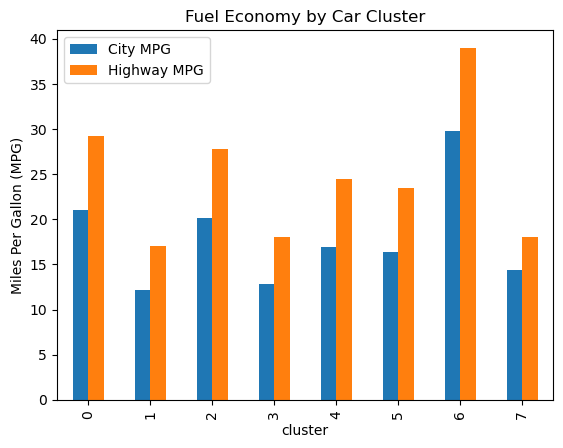

In [8]:
# Create a graph of fuel economy
df.groupby("cluster")[["cty", "hwy"]].mean().plot(kind="bar")
plt.ylabel("Miles Per Gallon (MPG)")
plt.title("Fuel Economy by Car Cluster")
plt.legend(["City MPG", "Highway MPG"])

plt.show()